<a href="https://colab.research.google.com/github/shashikawka/268452H-CS5998-Capstone-Project/blob/main/03_Isolation_Forest_Baseline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from pathlib import Path
from sklearn.ensemble import IsolationForest

In [4]:
data_dir = Path('/content/drive/MyDrive/CAPSTONE_PROJECT/processed_data')

X_train = np.load(data_dir / 'X_train.npy')
X_val = np.load(data_dir / 'X_val.npy')
X_eval = np.load(data_dir / 'X_eval.npy')

train_metadata = pd.read_csv(
    data_dir / 'train_metadata.csv',
    index_col=0,
    parse_dates=['timestamp']
)

val_metadata = pd.read_csv(
    data_dir / 'val_metadata.csv',
    index_col=0,
    parse_dates=['timestamp']
)

eval_metadata = pd.read_csv(
    data_dir / 'eval_metadata.csv',
    index_col=0,
    parse_dates=['timestamp']
)

sensor_features = joblib.load(
    data_dir / 'sensor_features.joblib'
)

print("Training data:", X_train.shape)
print("Validation data:", X_val.shape)
print("Evaluation data:", X_eval.shape)
print("Evaluation metadata:", eval_metadata.shape)

Training data: (423145, 15)
Validation data: (139419, 15)
Evaluation data: (954384, 15)
Evaluation metadata: (954384, 3)


In [5]:
print("Training values finite:", np.isfinite(X_train).all())
print("Validation values finite:", np.isfinite(X_val).all())
print("Evaluation values finite:", np.isfinite(X_eval).all())

print("\nTraining rows match metadata:",
      len(X_train) == len(train_metadata))

print("Validation rows match metadata:",
      len(X_val) == len(val_metadata))

print("Evaluation rows match metadata:",
      len(X_eval) == len(eval_metadata))

print("\nSensor features:")
print(sensor_features)

Training values finite: True
Validation values finite: True
Evaluation values finite: True

Training rows match metadata: True
Validation rows match metadata: True
Evaluation rows match metadata: True

Sensor features:
['TP2', 'TP3', 'H1', 'DV_pressure', 'Reservoirs', 'Oil_temperature', 'Motor_current', 'COMP', 'DV_eletric', 'Towers', 'MPG', 'LPS', 'Pressure_switch', 'Oil_level', 'Caudal_impulses']


##Step 1 : Train Isolation Forest

In [6]:
# Initialize the Isolation Forest baseline
isolation_forest = IsolationForest(
    n_estimators=100,
    max_samples=256,
    contamination='auto',
    random_state=42,
    n_jobs=-1
)

# Train using only the training dataset
isolation_forest.fit(X_train)

print("Isolation Forest training completed.")
print("Number of trees:", len(isolation_forest.estimators_))
print("Training observations:", X_train.shape[0])
print("Number of features:", X_train.shape[1])

Isolation Forest training completed.
Number of trees: 100
Training observations: 423145
Number of features: 15


##Step 2 : Calculate Anomaly Scores

In [7]:
train_scores = -isolation_forest.score_samples(X_train)
val_scores = -isolation_forest.score_samples(X_val)
eval_scores = -isolation_forest.score_samples(X_eval)

print("Training scores:", train_scores.shape)
print("Validation scores:", val_scores.shape)
print("Evaluation scores:", eval_scores.shape)

print("\nTraining score range:",
      train_scores.min(), "to", train_scores.max())

print("Validation score range:",
      val_scores.min(), "to", val_scores.max())

print("Evaluation score range:",
      eval_scores.min(), "to", eval_scores.max())

Training scores: (423145,)
Validation scores: (139419,)
Evaluation scores: (954384,)

Training score range: 0.3697132330893181 to 0.7490853451199639
Validation score range: 0.3725028980764983 to 0.7402302170115682
Evaluation score range: 0.37090827602726334 to 0.7526415059000232


##Step 3 : Visualize Score Distribution

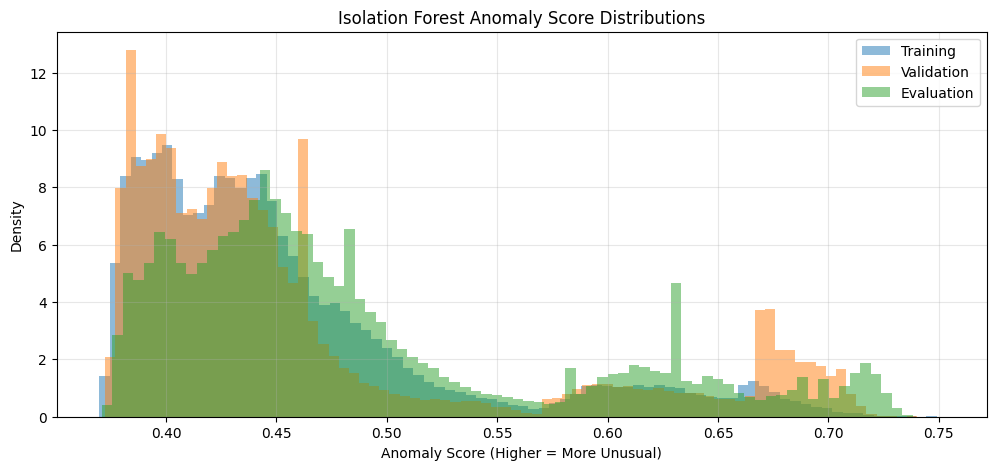

In [8]:
plt.figure(figsize=(12, 5))

plt.hist(train_scores, bins=80, alpha=0.5,
         density=True, label='Training')

plt.hist(val_scores, bins=80, alpha=0.5,
         density=True, label='Validation')

plt.hist(eval_scores, bins=80, alpha=0.5,
         density=True, label='Evaluation')

plt.xlabel('Anomaly Score (Higher = More Unusual)')
plt.ylabel('Density')
plt.title('Isolation Forest Anomaly Score Distributions')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

##### The trained Isolation Forest was applied separately to training,validation, and evaluation datasets, producing one anomaly score per observation. The score ranges are similar but not identical because each dataset contains different sensor observations.

##### Higher scores indicate more unusual behaviour, but these scores
##### are not failure probabilities. A threshold is still required
##### to classify observations as potential anomalies.

##Step 4 : Interpret the anomaly score statistics

In [9]:
import pandas as pd

score_summary = pd.DataFrame({
    'Training': train_scores,
}).describe()

for name, scores in [
    ('Training', train_scores),
    ('Validation', val_scores),
    ('Evaluation', eval_scores)
]:
    print(f"\n{name}")
    print("Mean:", round(scores.mean(), 4))
    print("Median:", round(np.median(scores), 4))
    print("95th percentile:", round(np.percentile(scores, 95), 4))
    print("99th percentile:", round(np.percentile(scores, 99), 4))


Training
Mean: 0.4562
Median: 0.4356
95th percentile: 0.6363
99th percentile: 0.6837

Validation
Mean: 0.4686
Median: 0.4336
95th percentile: 0.6835
99th percentile: 0.7062

Evaluation
Mean: 0.4879
Median: 0.4582
95th percentile: 0.6864
99th percentile: 0.7203


OBSERVATION :



#####Evaluation has the highest average anomaly score. -> model finds evaluation-period observations somewhat more unusual overall than training-period observations.
#####Validation has a higher 99th percentile than training. -> This indicates that the upper tail of validation scores is more extreme than the training upper tail, even though their medians are almost identical.
#####Evaluation has the highest 99th percentile. -> approximately 1% of evaluation observations have scores above that value.

##### Observation:
##### The evaluation dataset has a higher mean anomaly score (0.4879)
##### than training (0.4562) and validation (0.4686).
##### The 99th percentile is also highest for evaluation (0.7203),
##### suggesting more extreme unusual sensor patterns in this period.
##### However, these differences do not confirm failure detection.
##### Further evaluation against documented failure intervals is required.

##Step 5 : Select an anomaly detection threshold

In [10]:
# Select the 99th percentile of validation anomaly scores
threshold = np.percentile(val_scores, 99)

print("Selected anomaly threshold:", round(threshold, 4))

# Flag observations whose anomaly scores exceed the threshold
train_predictions = (train_scores > threshold).astype(int)
val_predictions = (val_scores > threshold).astype(int)
eval_predictions = (eval_scores > threshold).astype(int)

print("\nTraining anomalies:", train_predictions.sum())
print("Validation anomalies:", val_predictions.sum())
print("Evaluation anomalies:", eval_predictions.sum())

print("\nTraining anomaly rate:",
      round(train_predictions.mean() * 100, 2), "%")

print("Validation anomaly rate:",
      round(val_predictions.mean() * 100, 2), "%")

print("Evaluation anomaly rate:",
      round(eval_predictions.mean() * 100, 2), "%")

#1 means flagged as a potential anomaly, and 0 means not flagged.

Selected anomaly threshold: 0.7062

Training anomalies: 851
Validation anomalies: 1385
Evaluation anomalies: 31147

Training anomaly rate: 0.2 %
Validation anomaly rate: 0.99 %
Evaluation anomaly rate: 3.26 %


##### OBSERVATIONS :
##### Using the 99th percentile of validation scores (0.7062) as the anomaly threshold, the model flagged 0.20% of training observations,0.99% of validation observations, and 3.26% of evaluation observations.
##### The higher evaluation anomaly rate suggests that more sensor readings were considered unusual during the later operating period.
##### However, these predictions must be compared with documented failure intervals before assessing detection performance.

##Step 6 :  Compare predictions with documented failure intervals

In [11]:
# Create a copy of evaluation metadata
eval_results = eval_metadata.copy()

# Add Isolation Forest anomaly scores and predictions
eval_results['anomaly_score'] = eval_scores
eval_results['predicted_anomaly'] = eval_predictions

# Count predictions inside and outside documented failure intervals
comparison = pd.crosstab(
    eval_results['failure_period'],
    eval_results['predicted_anomaly']
)

print("Isolation Forest predictions vs documented failure periods:")
print(comparison)

# Calculate anomaly rates inside and outside failure intervals
failure_comparison = eval_results.groupby('failure_period').agg(
    observations=('predicted_anomaly', 'size'),
    flagged_anomalies=('predicted_anomaly', 'sum'),
    anomaly_rate=('predicted_anomaly', 'mean')
)

failure_comparison['anomaly_rate'] *= 100

print("\nAnomaly rates by period:")
print(failure_comparison.round(2))

Isolation Forest predictions vs documented failure periods:
predicted_anomaly       0      1
failure_period                  
0                  911020  13410
1                   12217  17737

Anomaly rates by period:
                observations  flagged_anomalies  anomaly_rate
failure_period                                               
0                     924430              13410          1.45
1                      29954              17737         59.21


##### OBSERVATIONS:
##### The Isolation Forest model flagged 17,737 out of 29,954 observations within documented failure periods, resulting in a 59.21% anomaly rate.
##### Outside these periods, only 1.45% of observations were flagged.This indicates that unusual sensor behaviour is substantially more
##### frequent during documented failure periods.However, the failure intervals are not precise point-level anomaly labels, so these results should not be interpreted directly as classification precision, recall, or false-positive rates.

##Step 7 : Evaluate each falure period

In [12]:
# Define the four documented failure intervals
failure_intervals = [
    ('Failure 1', '2020-04-18 00:00:00', '2020-04-18 23:59:00'),
    ('Failure 2', '2020-05-29 23:30:00', '2020-05-30 06:00:00'),
    ('Failure 3', '2020-06-05 10:00:00', '2020-06-07 14:30:00'),
    ('Failure 4', '2020-07-15 14:30:00', '2020-07-15 19:00:00')
]

failure_results = []

for name, start, end in failure_intervals:

    period_data = eval_results[
        (eval_results['timestamp'] >= start) &
        (eval_results['timestamp'] <= end)
    ]

    total = len(period_data)
    flagged = period_data['predicted_anomaly'].sum()

    failure_results.append({
        'failure': name,
        'observations': total,
        'flagged_anomalies': flagged,
        'anomaly_rate': (flagged / total * 100) if total > 0 else np.nan
    })

failure_summary = pd.DataFrame(failure_results)

print(failure_summary.round(2).to_string(index=False))

  failure  observations  flagged_anomalies  anomaly_rate
Failure 1          8657               1028         11.87
Failure 2          2360                891         37.75
Failure 3         17315              15663         90.46
Failure 4          1622                155          9.56


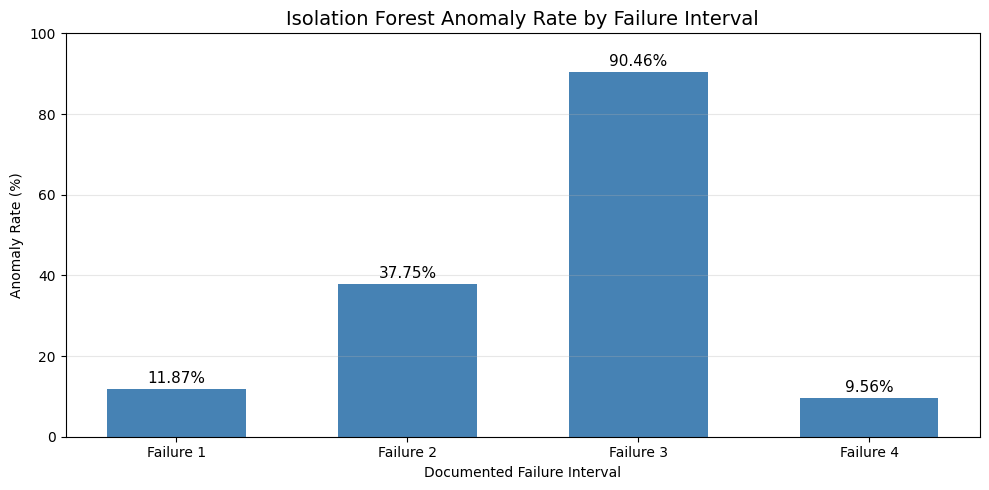

<Figure size 640x480 with 0 Axes>

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

bars = plt.bar(
    failure_summary['failure'],
    failure_summary['anomaly_rate'],
    color='steelblue',
    width=0.6
)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 1.5,
        f'{height:.2f}%',
        ha='center',
        fontsize=11
    )

plt.title('Isolation Forest Anomaly Rate by Failure Interval', fontsize=14)
plt.xlabel('Documented Failure Interval')
plt.ylabel('Anomaly Rate (%)')
plt.ylim(0, 100)
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

plt.savefig(
    '/content/drive/MyDrive/CAPSTONE_PROJECT/03_baseline/isolation_forest_failure_rates.png',
    dpi=300,
    bbox_inches='tight'
)

##### OBSERVATIONS:
##### The Isolation Forest baseline identified unusual sensor behaviour across all four documented failure intervals, but the anomaly rates varied considerably.
##### Failure 3 had the highest anomaly rate (90.46%), followed by
##### Failure 2 (37.75%), Failure 1 (11.87%), and Failure 4 (9.56%).
##### Failure 3 contributed approximately 88.3% of all anomaly flags recorded within the documented failure intervals.
##### Therefore, the overall failure-period anomaly rate of 59.21% is strongly influenced by Failure 3 and does not represent consistent detection performance across all failure events.

##Step 8 : Examine when anomalies first appeared

In [14]:
first_alert_results = []

for name, start, end in failure_intervals:

    period_data = eval_results[
        (eval_results['timestamp'] >= start) &
        (eval_results['timestamp'] <= end)
    ]

    flagged_data = period_data[
        period_data['predicted_anomaly'] == 1
    ]

    if not flagged_data.empty:
        first_alert = flagged_data['timestamp'].min()
        delay_minutes = (
            first_alert - pd.Timestamp(start)
        ).total_seconds() / 60
    else:
        first_alert = pd.NaT
        delay_minutes = np.nan

    first_alert_results.append({
        'failure': name,
        'failure_start': pd.Timestamp(start),
        'first_alert': first_alert,
        'delay_minutes': delay_minutes
    })

first_alert_summary = pd.DataFrame(first_alert_results)

print(first_alert_summary.to_string(index=False))

  failure       failure_start         first_alert  delay_minutes
Failure 1 2020-04-18 00:00:00 2020-04-18 00:24:28      24.466667
Failure 2 2020-05-29 23:30:00 2020-05-29 23:30:57       0.950000
Failure 3 2020-06-05 10:00:00 2020-06-05 10:00:34       0.566667
Failure 4 2020-07-15 14:30:00 2020-07-15 16:57:23     147.383333


##### OBSERVATION:
##### The Isolation Forest baseline produced anomaly alerts within the first minute of Failure 2 (57 seconds) and Failure 3 (34 seconds) after their documented start times.
##### Failure 1 had a detection delay of approximately 24 minutes,while Failure 4 had the longest delay of approximately 147 minutes.

##### However, these measurements represent the first flagged observations after failure onset, not advance failure prediction.

##Step 9 :  Investigate anomalies before failure onset

In [16]:
pre_failure_results = []

for name, start, end in failure_intervals:

    failure_start = pd.Timestamp(start)
    lookback_start = failure_start - pd.Timedelta(hours=24)

    # Use only the held-out evaluation period
    pre_failure_data = eval_results[
        (eval_results['timestamp'] >= lookback_start) &
        (eval_results['timestamp'] < failure_start)
    ]

    # Check whether the full 24-hour lookback is available
    full_lookback_available = (
        lookback_start >= eval_results['timestamp'].min()
    )

    flagged_data = pre_failure_data[
        pre_failure_data['predicted_anomaly'] == 1
    ]

    pre_failure_results.append({
        'failure': name,
        'full_24h_available': full_lookback_available,
        'observations': len(pre_failure_data),
        'flagged_anomalies': len(flagged_data),
        'before failure anomaly_rate': (
            len(flagged_data) / len(pre_failure_data) * 100
            if len(pre_failure_data) > 0 else np.nan
        )
    })

pre_failure_summary = pd.DataFrame(pre_failure_results)

print(pre_failure_summary.round(2).to_string(index=False))

  failure  full_24h_available  observations  flagged_anomalies  before failure anomaly_rate
Failure 1               False             0                  0                          NaN
Failure 2                True          7466                  7                         0.09
Failure 3                True          8716                 10                         0.11
Failure 4                True          6185                  3                         0.05


##### OBESERVATION:
##### The Isolation Forest baseline identified very few anomalous observations during the 24 hours preceding documented failures.
##### Failure 2 had 7 flagged observations (0.09%), Failure 3 had 10 (0.11%), and Failure 4 had 3 (0.05%). Failure 1 could not be evaluated because its preceding 24-hour period was outside the held-out evaluation dataset.
##### Compared with the much higher anomaly rates during failures, these results suggest that the baseline is more responsive to abnormal behaviour during failure intervals than beforehand.
##### However, the presence of a few pre-failure alerts does not establish reliable advance failure prediction.

##Step 10 :  Find the last anomaly alert before each failure

In [17]:
pre_failure_alert_timing = []

for name, start, end in failure_intervals:

    failure_start = pd.Timestamp(start)
    lookback_start = failure_start - pd.Timedelta(hours=24)

    # Exclude failures without a complete evaluation lookback
    if lookback_start < eval_results['timestamp'].min():
        continue

    pre_failure_data = eval_results[
        (eval_results['timestamp'] >= lookback_start) &
        (eval_results['timestamp'] < failure_start) &
        (eval_results['predicted_anomaly'] == 1)
    ]

    if not pre_failure_data.empty:
        last_alert = pre_failure_data['timestamp'].max()

        lead_time_minutes = (
            failure_start - last_alert
        ).total_seconds() / 60
    else:
        last_alert = pd.NaT
        lead_time_minutes = np.nan

    pre_failure_alert_timing.append({
        'failure': name,
        'last_pre_failure_alert': last_alert,
        'minutes_before_failure': lead_time_minutes
    })

pre_failure_timing_summary = pd.DataFrame(
    pre_failure_alert_timing
)

print(pre_failure_timing_summary.round(2).to_string(index=False))

  failure last_pre_failure_alert  minutes_before_failure
Failure 2    2020-05-29 23:28:58                    1.03
Failure 3    2020-06-05 09:59:34                    0.43
Failure 4    2020-07-15 11:44:39                  165.35


##### OBSERVATION:
##### The last pre-failure anomaly alert occurred approximately 1 minute before Failure 2 and 26 seconds before Failure 3.
##### For Failure 4, the last alert occurred approximately 165 minutes before the documented failure start.
##### These results indicate that Isolation Forest detected unusual sensor behaviour before some documented failure intervals.
##### However, the low number of pre-failure alerts and variation in their timing do not establish reliable early prediction.
##### Further analysis is required to determine whether these alerts represent meaningful warning patterns or isolated anomalies.

##Step 11 :  Visualize anomaly scores around a failure

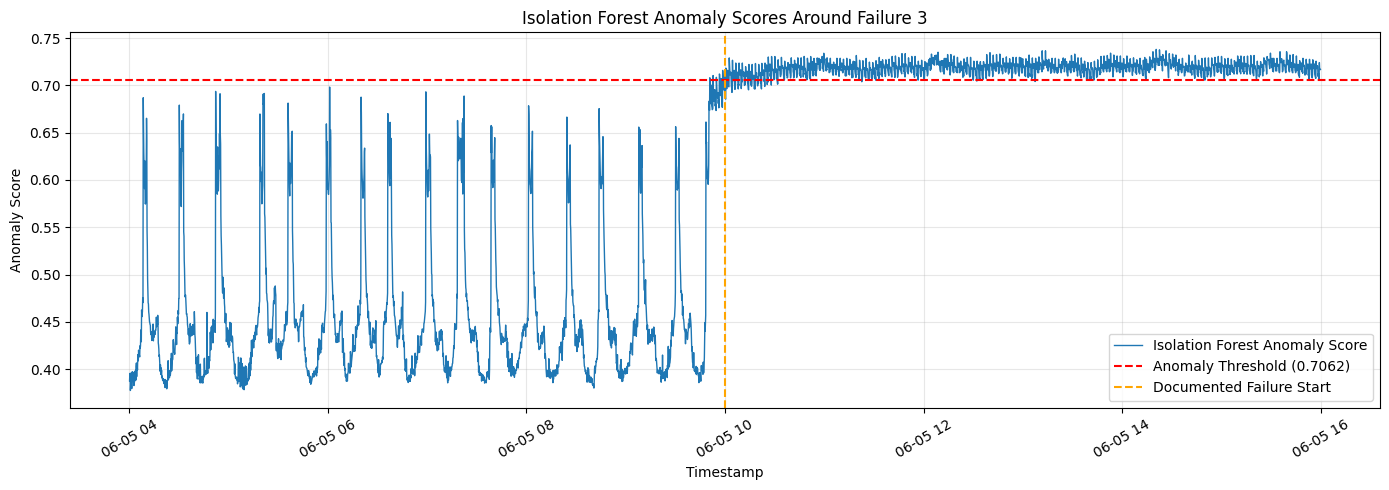

<Figure size 640x480 with 0 Axes>

In [21]:
# Failure 3 start time
failure_start = pd.Timestamp('2020-06-05 10:00:00')

# Select 6 hours before and after failure start
plot_start = failure_start - pd.Timedelta(hours=6)
plot_end = failure_start + pd.Timedelta(hours=6)

plot_data = eval_results[
    (eval_results['timestamp'] >= plot_start) &
    (eval_results['timestamp'] <= plot_end)
].copy()

plt.figure(figsize=(14, 5))

# Plot anomaly scores
plt.plot(
    plot_data['timestamp'],
    plot_data['anomaly_score'],
    label='Isolation Forest Anomaly Score',
    linewidth=1
)

# Show selected anomaly threshold
plt.axhline(
    y=threshold,
    color='red',
    linestyle='--',
    label=f'Anomaly Threshold ({threshold:.4f})'
)

# Mark documented failure start
plt.axvline(
    x=failure_start,
    color='orange',
    linestyle='--',
    label='Documented Failure Start'
)

plt.title('Isolation Forest Anomaly Scores Around Failure 3')
plt.xlabel('Timestamp')
plt.ylabel('Anomaly Score')
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

plt.savefig(
    '/content/drive/MyDrive/CAPSTONE_PROJECT/03_baseline/isolation_forest_anomaly_scores_around_failure_3.png',
    dpi=300,
    bbox_inches='tight'
)

##### OBSERVATIONS:
##### Before Failure 3, anomaly scores showed repeated fluctuations and occasional spikes, with most values below the selected anomaly threshold of 0.7062(0.71).
##### Near the documented failure start, the scores increased sharply and remained elevated throughout the displayed failure period.
##### This suggests a sustained change in sensor behaviour rather than isolated anomalous observations.
##### The pattern is consistent with the high anomaly rate (90.46%) recorded for Failure 3.
##### However, the observed change does not establish reliable advance failure prediction.

##Step 12 :  Visualize all four failure intervals

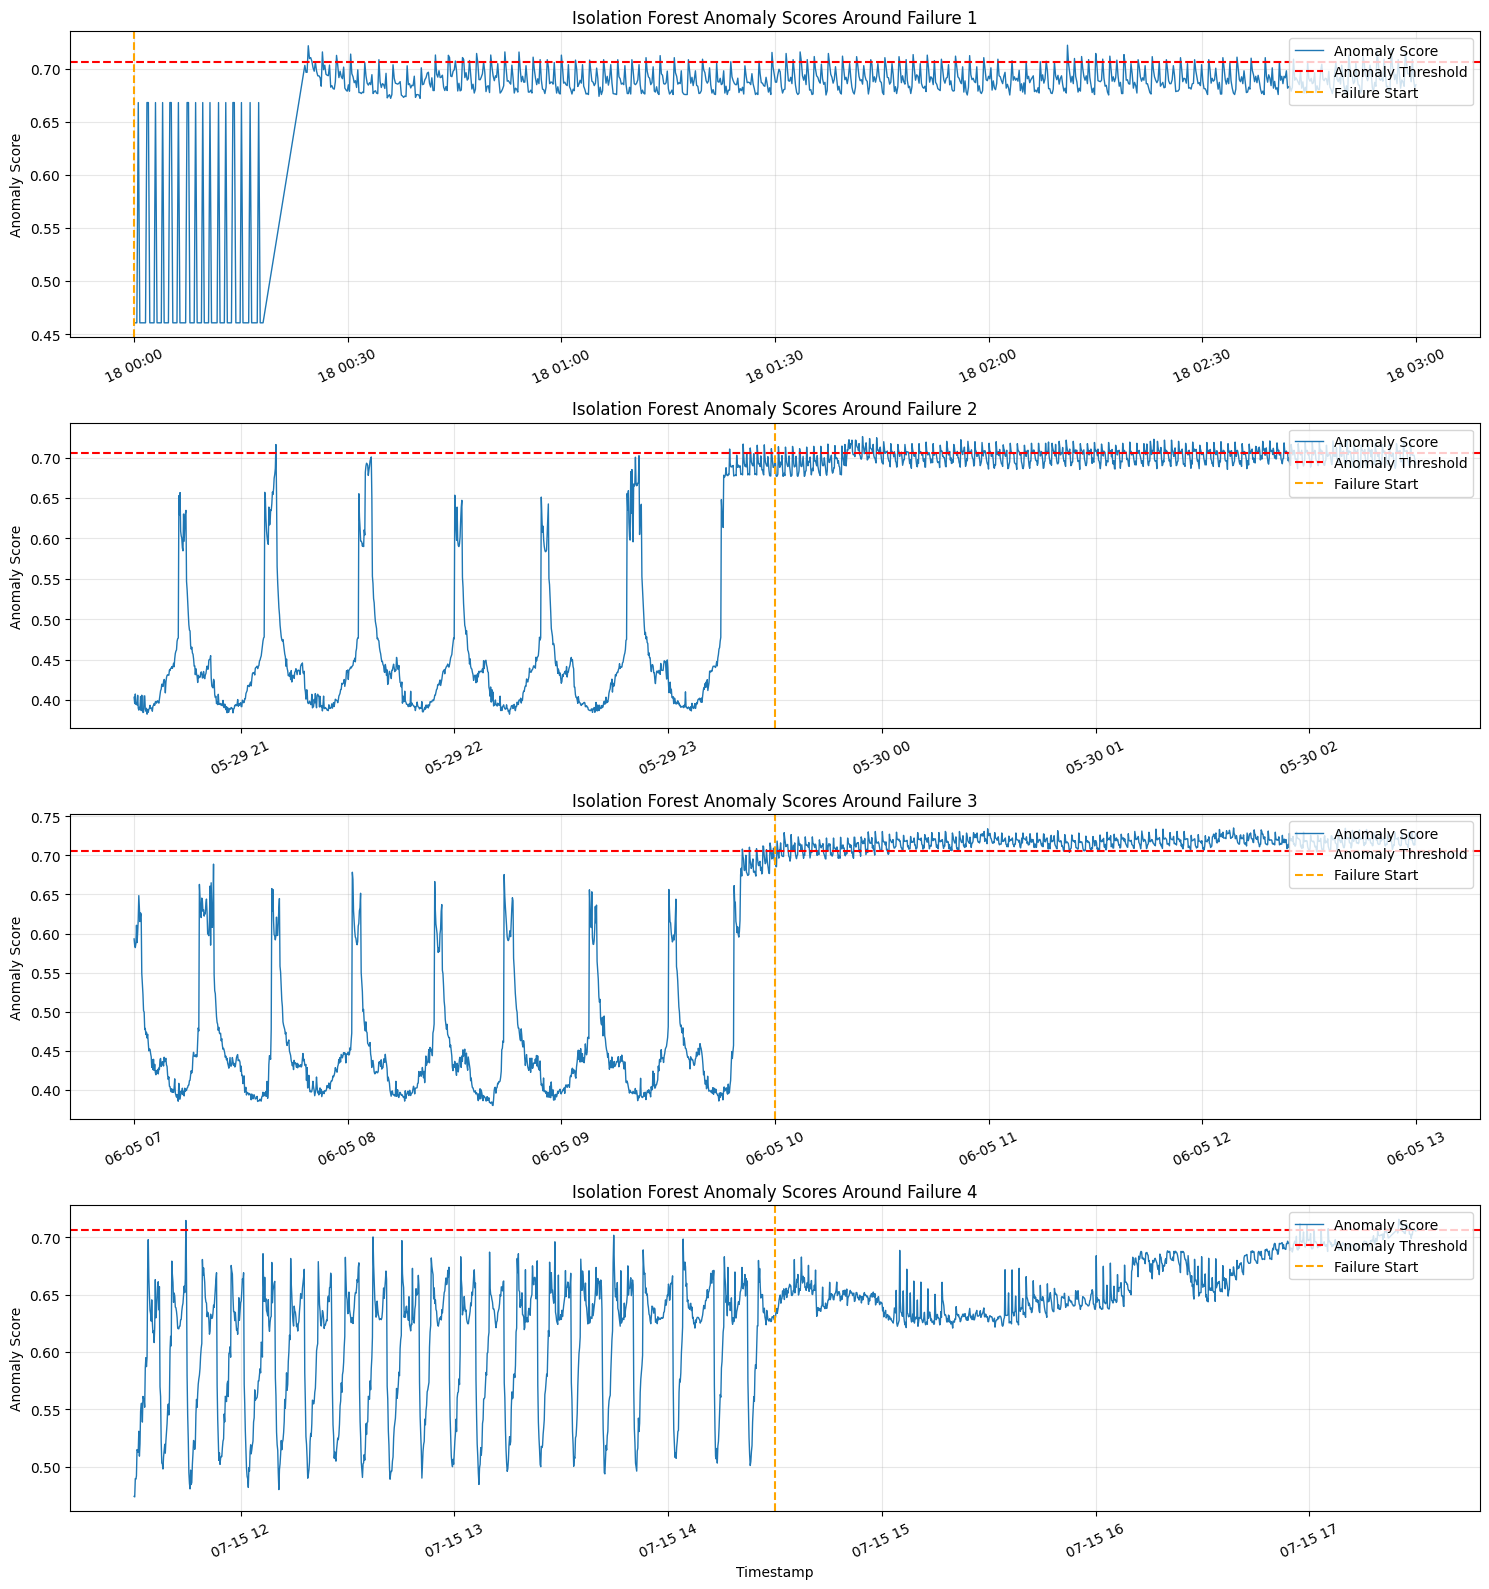

<Figure size 640x480 with 0 Axes>

In [23]:
fig, axes = plt.subplots(4, 1, figsize=(15, 16))

for ax, (name, start, end) in zip(axes, failure_intervals):

    failure_start = pd.Timestamp(start)

    # Plot 3 hours before and 3 hours after failure start
    plot_start = failure_start - pd.Timedelta(hours=3)
    plot_end = failure_start + pd.Timedelta(hours=3)

    plot_data = eval_results[
        (eval_results['timestamp'] >= plot_start) &
        (eval_results['timestamp'] <= plot_end)
    ]

    ax.plot(
        plot_data['timestamp'],
        plot_data['anomaly_score'],
        linewidth=1,
        label='Anomaly Score'
    )

    ax.axhline(
        threshold,
        color='red',
        linestyle='--',
        label='Anomaly Threshold'
    )

    ax.axvline(
        failure_start,
        color='orange',
        linestyle='--',
        label='Failure Start'
    )

    ax.set_title(f'Isolation Forest Anomaly Scores Around {name}')
    ax.set_ylabel('Anomaly Score')
    ax.grid(alpha=0.3)
    ax.legend(loc='upper right')
    ax.tick_params(axis='x', rotation=25)

plt.xlabel('Timestamp')
plt.tight_layout()
plt.show()

plt.savefig(
    '/content/drive/MyDrive/CAPSTONE_PROJECT/03_baseline/Isolation Forest Anomaly Scores Around.png',
    dpi=300,
    bbox_inches='tight'
)

##### Observation:
##### The Isolation Forest anomaly-score patterns varied considerably across the four documented failure intervals.
##### Failures 2 and 3 showed noticeable changes toward sustained elevated anomaly scores around their documented start times.
##### Failure 3 exhibited the clearest pattern, consistent with its high anomaly rate of 90.46%.
##### Failure 1 showed elevated scores but relatively few threshold exceedances, while Failure 4 remained mostly below the threshold.
##### These results indicate that the baseline is more responsive to some failure-related sensor patterns than others.
##### Apparent transitions should also be checked for recording gaps before being interpreted as continuous sensor behaviour.

##Step 13 : Check recording gaps around failure onset

In [24]:
# Check recording gaps within 3 hours after each failure start

for name, start, end in failure_intervals:

    failure_start = pd.Timestamp(start)

    period_data = eval_results[
        (eval_results['timestamp'] >= failure_start) &
        (eval_results['timestamp'] <= failure_start + pd.Timedelta(hours=3))
    ].copy()

    period_data['time_gap'] = period_data['timestamp'].diff()

    large_gaps = period_data[
        period_data['time_gap'] > pd.Timedelta(minutes=1)
    ]

    print(f"\n{name}")
    print("Recording gaps > 1 minute:", len(large_gaps))

    if not large_gaps.empty:
        print(
            large_gaps[['timestamp', 'time_gap']]
            .to_string(index=False)
        )


Failure 1
Recording gaps > 1 minute: 1
          timestamp        time_gap
2020-04-18 00:23:59 0 days 00:05:52

Failure 2
Recording gaps > 1 minute: 0

Failure 3
Recording gaps > 1 minute: 0

Failure 4
Recording gaps > 1 minute: 1
          timestamp        time_gap
2020-07-15 17:24:39 0 days 00:02:19


##### Observation:
##### Recording-gap analysis identified one gap of 5 minutes and 52 seconds during Failure 1 and one gap of 2 minutes and 19 seconds during Failure 4.
##### No recording gaps greater than one minute were identified during the first three hours of Failures 2 and 3.
##### The gap in Failure 1 explains an apparent straight-line transition in the anomaly-score visualization, which should not be interpreted as continuous sensor behaviour.
##### Overall, recording gaps must be considered when interpretin anomaly-score patterns and detection timing.

##Step 14 : Save the Isolation Forest baseline results

In [26]:
# Create directory for baseline model outputs
baseline_dir = data_dir.parent / 'isolation_forest_results'
baseline_dir.mkdir(parents=True, exist_ok=True)

# Save trained model and selected threshold
joblib.dump(
    isolation_forest,
    baseline_dir / 'isolation_forest_model.joblib'
)

joblib.dump(
    threshold,
    baseline_dir / 'isolation_forest_threshold.joblib'
)

# Save anomaly scores and predictions
np.save(baseline_dir / 'train_scores.npy', train_scores)
np.save(baseline_dir / 'val_scores.npy', val_scores)
np.save(baseline_dir / 'eval_scores.npy', eval_scores)

np.save(baseline_dir / 'eval_predictions.npy', eval_predictions)

# Save evaluation results with timestamps
eval_results.to_csv(
    baseline_dir / 'isolation_forest_evaluation.csv',
    index=False
)

print("Isolation Forest baseline results saved successfully.")
print("Output directory:", baseline_dir)

Isolation Forest baseline results saved successfully.
Output directory: /content/drive/MyDrive/CAPSTONE_PROJECT/isolation_forest_results
